# Module 5 — Worksheet 5: Random Forests and Boosted Trees
**ISA 591 — Introduction to Data Mining in Business**

**Business application:** Predicting customer churn with tree-based models.

**Instructions:** Run the code cells in order. For the `TODO` exercises, complete or modify a few lines and answer the interpretation questions.

## Learning goals

1. Explain why boosted trees are built **sequentially**.
2. Fit `GradientBoostingClassifier` and compare it with a tree and a Random Forest.
3. Interpret performance and recommend a model for a business problem.


---
## 1. Customer churn problem

A telecommunications company wants to predict whether a customer will **churn** (leave the company).

- **Target:** `Churn` (`Yes` = 1, `No` = 0).
- **Predictors:** Contract type, tenure, monthly charges, services, and other customer characteristics.

We will use **the same Telco churn dataset** across the exercises.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset used in this module
df = pd.read_csv(
    'https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/Telco_Churn.csv'
)

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Practice 1A — Check the target

What fraction of customers left the company? Is the target balanced?

In [2]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True))

# Write your conclusion below in the Markdown response cell.

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


**Your response:**

-

## 2. Prepare the data

We will use the same straightforward approach as the other tree worksheets:

1. Convert `TotalCharges` to a numeric variable.
2. Remove the customer ID.
3. Convert the target to 0 and 1.
4. Dummy-encode categorical predictors.
5. Create training and test datasets.

We will calculate missing-value medians from **training data only**.

In [3]:
# Convert TotalCharges, which may contain blank strings
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Remove the ID; it is not a meaningful predictor
df.drop(columns='customerID', inplace=True)

# Convert the response to 0/1
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

# Convert categorical variables to dummy variables
df = pd.get_dummies(df, drop_first=True, dtype=int)

print('Remaining missing values:', df.isna().sum().sum())
print('Prepared shape:', df.shape)
df.head()

Remaining missing values: 11
Prepared shape: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='Churn')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=591, stratify=y
)

# Learn the median on the training data and apply it to both sets
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print('Training shape:', X_train.shape)
print('Test shape:', X_test.shape)

Training shape: (4930, 30)
Test shape: (2113, 30)


**Quick check:** Why should a customer be in either the training set or the test set, but not both?

**Your response:**

-

---
## 3. Baseline: One decision tree

A single decision tree predicts churn using a sequence of `IF / THEN` rules. Deep trees can fit the training data very closely and may overfit.

Decision Tree accuracy: 0.7681
Confusion matrix:


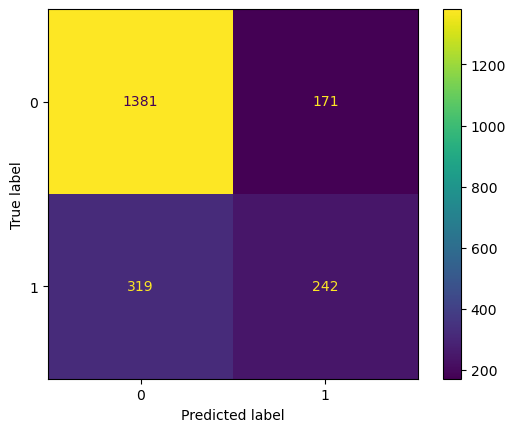

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

dt = DecisionTreeClassifier(max_depth=4, random_state=591)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print('Decision Tree accuracy:', round(accuracy_score(y_test, y_pred_dt), 4))
print('Confusion matrix:')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_dt)).plot();

In [ ]:
## We are expecting to catch [RECALL] 242 / (242 + 319) = 43% of likely churners (DECISION TREE)
242 / (242 + 319)

0.43137254901960786

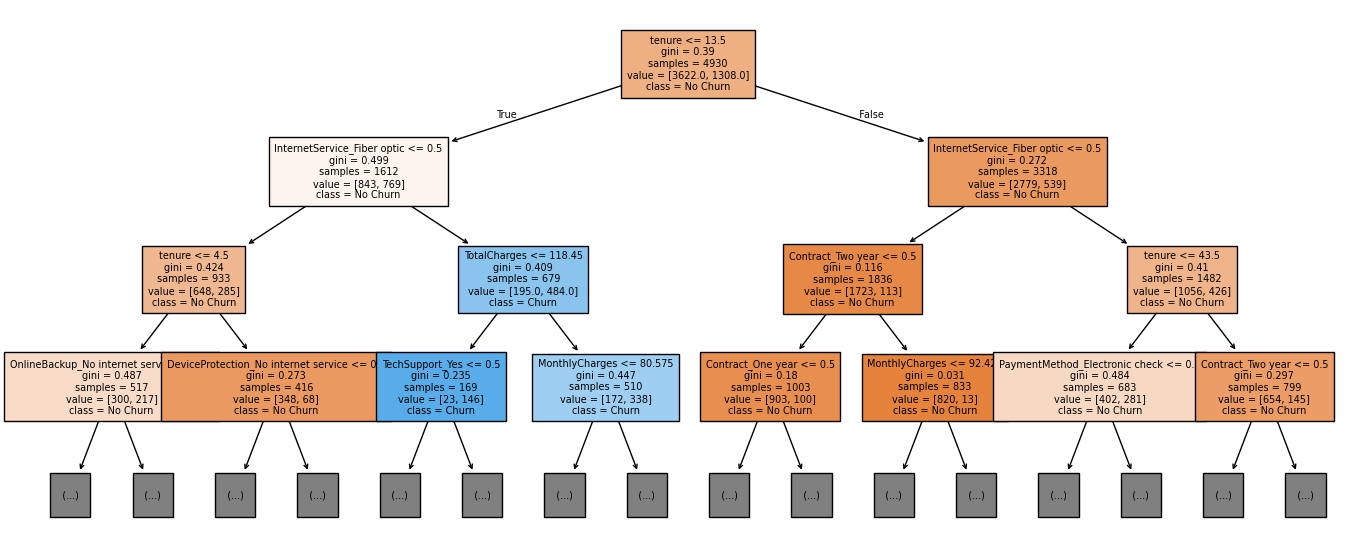

In [18]:
# Visualize only the top part of the decision tree
plt.figure(figsize=(17, 7))
plot_tree(dt, feature_names=X_train.columns,
          class_names=['No Churn', 'Churn'],
          filled=True, fontsize=7, max_depth = 3)
plt.show()

In [14]:
## GINI (root)
#### remember gini = 2*p1*p2
p1 = 3622 / 4930 ## proportion of customers who DID NOT churn
p2 = 1308 / 4930 ## proportion of customers who churned
gini_root = 2*p1*p2
print(f'Gini (root): {gini_root}')

## GINI (left child node)
gini_left = 0.499

## GINI (right child node)
gini_right = 0.272

## GINI (combined children nodes)
gini_combined = 1612/4930*gini_left + 3318/4930*gini_right
print(f'Gini (combined children nodes): {gini_combined}')

## IMPROVEMENT - GAIN - IMPURITY DECREASE
gini_improvement = gini_root - gini_combined
print(f'Gini (Improvement) -- GAIN -- Impurity Decrease : {gini_improvement}')
print(f'This is the BEST improvement found out of EVERY SINGLE VARIABLE - AND - EVERY POSSIBLE SPLIT IN EACH ONE')


Gini (root): 0.38984533982859426
Gini (combined children nodes): 0.3462239350912779
Gini (Improvement) -- GAIN -- Impurity Decrease : 0.04362140473731635
This is the BEST improvement found out of EVERY SINGLE VARIABLE - AND - EVERY POSSIBLE SPLIT IN EACH ONE


**Practice 3A — Interpretation:** Identify the variable used at the root. What does the split tell you about the company's customers?

**Your response:**

-

---
## 4. Random Forests: Many trees instead of one

A **Random Forest** combines many decision trees. Each tree uses:

- A **bootstrap sample** of training observations (sampling with replacement).
- A **random subset of predictors considered at each split**, making the trees less alike.

For classification, a forest predicts a class by combining trees' votes. It estimates class probabilities by **averaging the trees' class probabilities**.

**Important parameters:** `n_estimators` = number of trees, `max_depth` = limit on tree depth, and `max_features` = number of candidate predictors at each split.

### Practice 4A — Majority vote

Suppose five trees classify one customer as:

`[1, 0, 1, 1, 0]`

What is the majority-vote predicted class? How many trees voted for churn?

In [19]:
## RANDOM FOREST
#### n_estimators = number of trees combined
#### bootstrap sample of the obs (samples with replacement)
#### random sample of the vars 

from sklearn.ensemble import RandomForestClassifier

rf_small = RandomForestClassifier(
    n_estimators=3,
    max_depth=2,
    max_features='sqrt',
    random_state=591
)

rf_small.fit(X_train, y_train)
print('Number of fitted trees:', len(rf_small.estimators_))

Number of fitted trees: 3


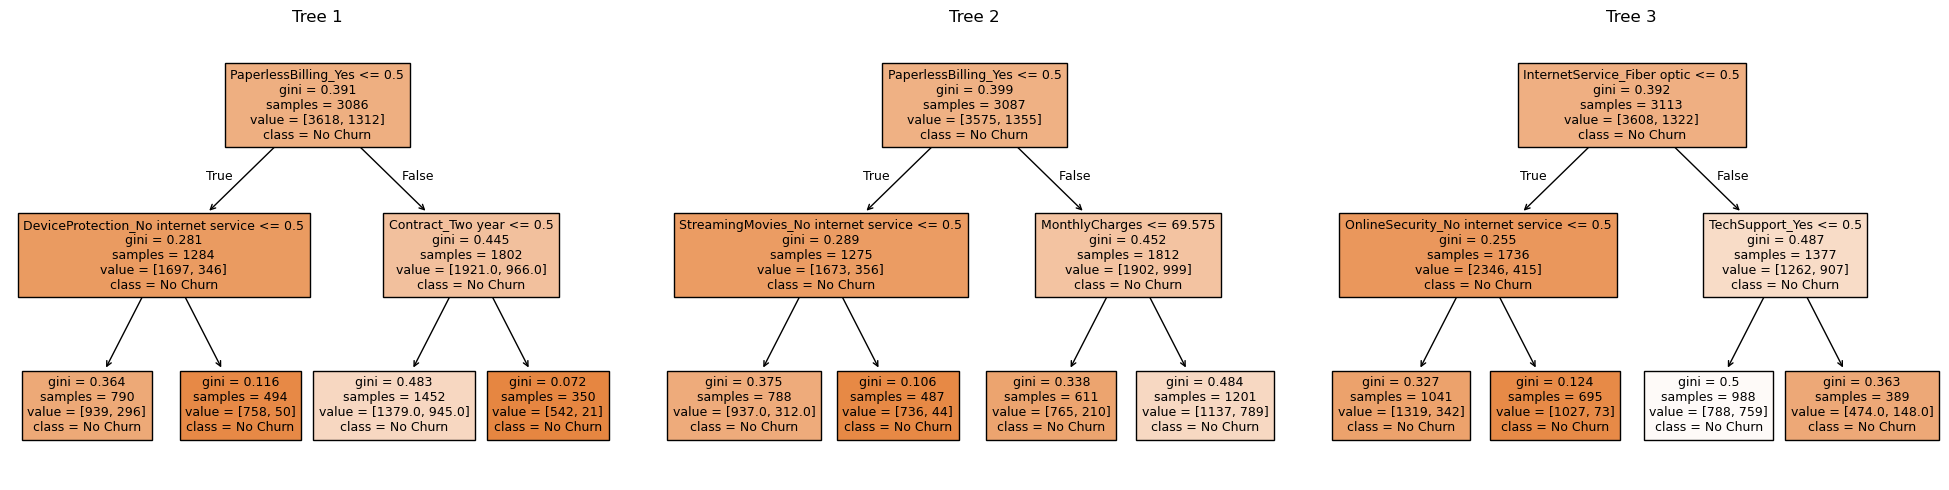

In [20]:
# Each tree can have different splits
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for i in range(3):
    plot_tree(rf_small.estimators_[i],
              feature_names=X_train.columns,
              class_names=['No Churn', 'Churn'],
              filled=True, fontsize=9, ax=axes[i])
    axes[i].set_title(f'Tree {i + 1}')

plt.tight_layout()
plt.show()

In [ ]:
## FITTING 3 TREES
## Suppose
#### TENURE = 20 MONTHS
#### PAPERLESS BILLING = "YES"
#### CONTRACT TWO YEAR = "YES"
#### MONTHLY CHARGES = $50
#### SERVICE FIBER OPTIC = "NO"

## TREE # 1
#### prediction = "NO CHURN" - yhat = 0
#### probability of churn = P(CHURN) = 21/(542+21) = 3.7% ----- 542+21 are BOOTSTRAP SAMPLES OF 350 

## TREE # 2
#### prediction = "NO CHURN"
#### probability of churn = 210 / (765+210)  = 21.5%

## TREE # 3

## FINAL PREDICTION : "NO CHURN" because of majority vote
## FINAL PROBABILITY: (0.037 + 0.215 + ...) / 3


## RF -- ADVANTAGES
#### AVERAGE OR MAJORITY VOTE makes it a more robust predictive model
## RF --- DISADVANTAGE
#### INTERPRETABILITY

0.2153846153846154

### Practice 4B — Forest predictions

Compare the predictions of the three individual trees with the final forest prediction. Can different trees disagree?

For this cell, each tree's `.predict()` returns 0 or 1. The Random Forest's `.predict_proba()` averages the trees' class probabilities; this is not necessarily equal to the fraction of hard votes.

In [25]:
# Predictions for the first five test customers
first_five = X_test.iloc[:5]

for i, tree in enumerate(rf_small.estimators_):
    print(f'Tree {i + 1}:', tree.predict(first_five))

print('Forest predicted classes:', rf_small.predict(first_five))
print('Forest churn probabilities:',
      np.round(rf_small.predict_proba(first_five)[:, 1], 3))

Tree 1: [0. 0. 0. 0. 0.]
Tree 2: [0. 0. 0. 0. 0.]
Tree 3: [0. 0. 0. 0. 0.]
Forest predicted classes: [0 0 0 0 0]
Forest churn probabilities: [0.062 0.218 0.436 0.436 0.218]


c:\Users\martinwg\.conda\envs\intro-data-mining\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\martinwg\.conda\envs\intro-data-mining\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\martinwg\.conda\envs\intro-data-mining\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


**Your response:** Why can the Random Forest be more stable than relying on a single tree?

-

---
## 5. Train a more realistic Random Forest

Increasing `n_estimators` generally makes the ensemble more stable. Let's use 100 trees.

In [ ]:
## HOW TO TRAIN A RANDOM FOREST
#### try initially with 50 to 100 trees
#### if dataset is too large, then use max_samples (fraction that by default is 1 --- change to lower percentage)
#### try measuring performance with OOB obs (NOT THE TEST SET)

rf = RandomForestClassifier(
    n_estimators=50,
    random_state=591,
    n_jobs=-1, 
    max_samples = 0.10, 
    oob_score=True
)

rf.fit(X_train, y_train)
print(f'This is the OOB SCORE estimated on the training: {rf.oob_score_}')

########################################################################################
## DO NOT GET TEST SET PERFORMANCE WHEN TRYING TO GET BEST HYPERPARAMETERS
## LEAVE THIS FOR LAST 
# y_pred_rf = rf.predict(X_test)

#print('Random Forest accuracy:', round(accuracy_score(y_test, y_pred_rf), 4))
#print('Confusion matrix:')
#print(confusion_matrix(y_test, y_pred_rf))

This is the OOB SCORE estimated on the training: 0.8056795131845842


In [33]:
## THEN AFTER A GOOD IDEA ON THE NUMBER OF TREES COMBINED, max_depth, min_impurity_decrease
#### FULL GRID SEARCH

### Practice 5A — Compare the single tree and the forest

Which model has higher test accuracy? Does a better accuracy necessarily mean better detection of customers who churn?

In [34]:
from sklearn.metrics import recall_score, precision_score, roc_auc_score

print('Single tree:')
print('  Accuracy:', round(accuracy_score(y_test, dt.predict(X_test)), 4))
print('  Recall:', round(recall_score(y_test, dt.predict(X_test)), 4))

print('Random Forest:')
print('  Accuracy:', round(accuracy_score(y_test, rf.predict(X_test)), 4))
print('  Recall:', round(recall_score(y_test, rf.predict(X_test)), 4))

Single tree:
  Accuracy: 0.7681
  Recall: 0.4314
Random Forest:
  Accuracy: 0.797
  Recall: 0.4795


**Your response:**

-

### Practice 5B — Change one hyperparameter

Create a second forest using **200 trees** and `max_depth=5`. Compare its test accuracy to the original forest.

In [35]:
# TODO: Change the n_estimators and max_depth values below
rf_2 = RandomForestClassifier(
    n_estimators=200,       # change to 200
    max_depth=5,        # change to 5
    random_state=591,
    n_jobs=-1
)

rf_2.fit(X_train, y_train)

print('Original RF accuracy:', round(accuracy_score(y_test, rf.predict(X_test)), 4))
print('Modified RF accuracy:', round(accuracy_score(y_test, rf_2.predict(X_test)), 4))

Original RF accuracy: 0.797
Modified RF accuracy: 0.787


**Concept question:** Why is using test accuracy repeatedly to choose the best hyperparameters a bad practice? (In a real project, tune with cross-validation on the training data.)

**Your response:**

-

---
## 7. Boosting: A different way to combine trees

**Random Forest:** Trees are built independently, then their predictions are aggregated.

**Boosting:** Trees are added **sequentially**. Each new tree attempts to improve the predictions made by the existing ensemble.

For squared-error regression, we can think of a new tree as fitting the current **residuals**. For classification, gradient boosting uses the negative gradients of its classification loss (often called *pseudo-residuals*). The most important operation is:

$$
\boxed{F_m(x) = F_{m-1}(x) + \eta\,h_m(x)}
$$

where $F_m(x)$ is the initial prediction and $h_m(x)$ is the next tree trained on the residuals of the previous tree.

Two important hyperparameters:

- `n_estimators`: number of boosting stages (trees in binary classification).
- `learning_rate`: size of each new stage's contribution.

In [36]:
## RF
### tree # 1: fit(X_train_B1, y_train_B1)
### tree # 2: fit(X_train_B2, y_train_B2)
### ....
### n_estimators
### n_jobs = -1 (number of cores = 10 --- fit 1 tree per core)


### BOOSTED TREES
## F0 (tree # 1)   fit on (X_train, y_train)   --- predicts yhat0 --- computes e0 = (y_train - yhat0)
## F1 (tree # 2)   = F0 + learning_rate*h      ----  h is fit (X_train, e0) --- computes e1 = (y_train - yhat1)
## F2 (tree # 3)   = F1 + learning_rate*h      ----  h is fit (X_train, e1) --- computes e2 = (y_train - yhat2)
## ...
## n_estimators

## CANNOT FIT F2 if I dont have F1
## still can n_jobs = -1 for calculations within each tree to be parallelized

### Example

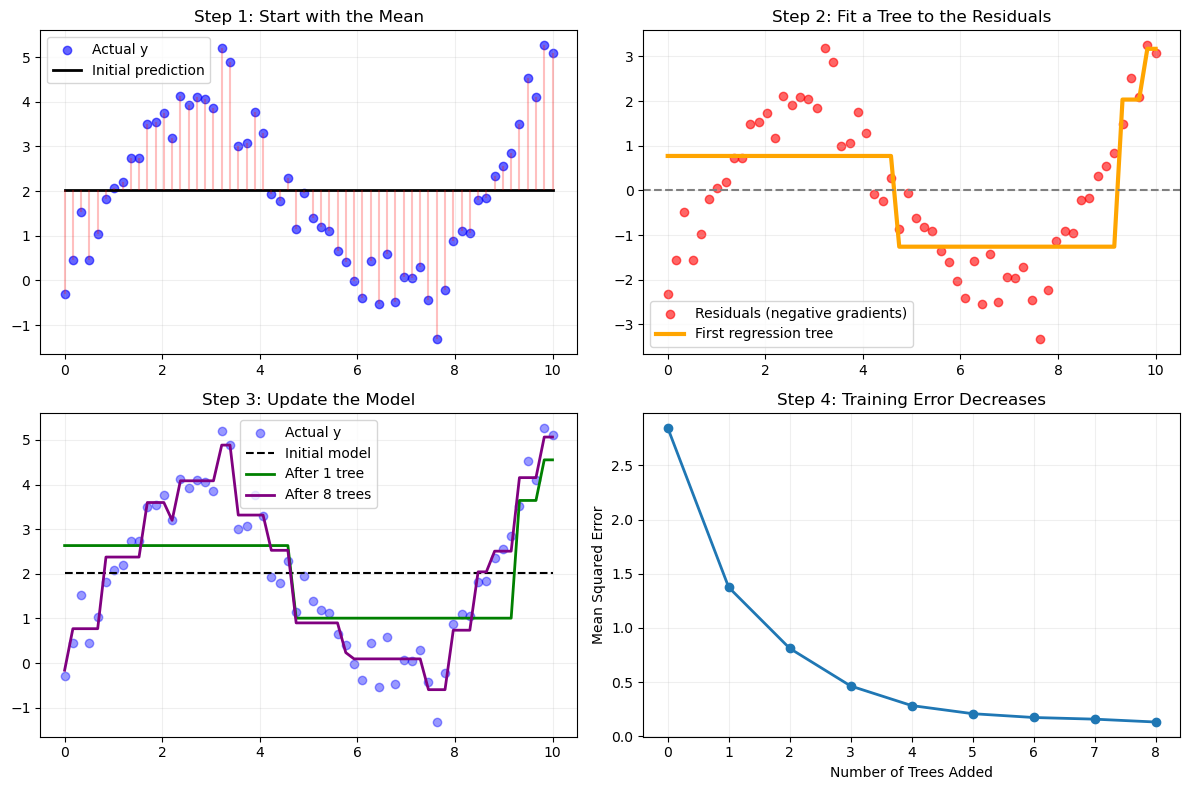

In [41]:
from sklearn.tree import DecisionTreeRegressor

# --------------------------------------------------
# 1. Generate a simple regression dataset
# --------------------------------------------------
np.random.seed(591)

x = np.linspace(0, 10, 60)
y = 3 * np.sin(x / 1.5) + 0.4 * x + np.random.normal(0, 0.5, 60)

X = x.reshape(-1, 1)
learning_rate = 0.8

# --------------------------------------------------
# 2. Initial model: predict the mean
# --------------------------------------------------
F0 = np.full(len(y), y.mean())

# Negative gradient for squared-error loss = residual
residuals = y - F0

# --------------------------------------------------
# 3. Fit the first tree to the residuals
# --------------------------------------------------
tree = DecisionTreeRegressor(max_depth=2, random_state=591)
tree.fit(X, residuals)

tree_prediction = tree.predict(X)

# Update the model
F1 = F0 + learning_rate * tree_prediction

# --------------------------------------------------
# 4. Continue boosting (7 more trees)
# --------------------------------------------------
F = F1.copy()

mse = [
    np.mean((y - F0)**2),
    np.mean((y - F1)**2)
]

for i in range(7):

    residuals_new = y - F

    tree = DecisionTreeRegressor(max_depth=2, random_state=591)
    tree.fit(X, residuals_new)

    F = F + learning_rate * tree.predict(X)

    mse.append(np.mean((y - F)**2))

# --------------------------------------------------
# 5. Visualize the process
# --------------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# Initial model
ax[0, 0].scatter(x, y, color="blue", alpha=0.6, label="Actual y")
ax[0, 0].plot(x, F0, color="black", linewidth=2, label="Initial prediction")
ax[0, 0].vlines(x, F0, y, color="red", alpha=0.25)
ax[0, 0].set_title("Step 1: Start with the Mean")
ax[0, 0].legend()

# Fit a tree to the negative gradients (residuals)
ax[0, 1].scatter(x, y - F0, color="red", alpha=0.6,
                 label="Residuals (negative gradients)")
ax[0, 1].plot(x, tree_prediction, color="orange", linewidth=3,
              label="First regression tree")
ax[0, 1].axhline(0, color="gray", linestyle="--")
ax[0, 1].set_title("Step 2: Fit a Tree to the Residuals")
ax[0, 1].legend()

# Update predictions
ax[1, 0].scatter(x, y, color="blue", alpha=0.4, label="Actual y")
ax[1, 0].plot(x, F0, "k--", label="Initial model")
ax[1, 0].plot(x, F1, color="green", linewidth=2, label="After 1 tree")
ax[1, 0].plot(x, F, color="purple", linewidth=2, label="After 8 trees")
ax[1, 0].set_title("Step 3: Update the Model")
ax[1, 0].legend()

# Training loss decreases
ax[1, 1].plot(range(len(mse)), mse, marker="o", linewidth=2)
ax[1, 1].set_title("Step 4: Training Error Decreases")
ax[1, 1].set_xlabel("Number of Trees Added")
ax[1, 1].set_ylabel("Mean Squared Error")
ax[1, 1].set_xticks(range(len(mse)))

for a in ax.flat:
    a.grid(alpha=0.2)

plt.tight_layout()
plt.show()

---
## 8. Fit Gradient Boosting on the Telco data

We use `GradientBoostingClassifier` directly. The code is intentionally similar to fitting a Random Forest.

In [42]:
## THE DEFAULT LEARNING RATE WILL BE SMALL 
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.10,
    max_depth=2,
    random_state=591
)

gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

print('Gradient Boosting accuracy:', round(accuracy_score(y_test, y_pred_gb), 4))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred_gb))

Gradient Boosting accuracy: 0.796
Confusion matrix:
[[1403  149]
 [ 282  279]]


### Practice 8A — Experiment with the learning rate

Try a smaller learning rate in a second model. Keep the other settings unchanged and compare the models. A lower learning rate can require more boosting stages.

In [27]:
# TODO: Try learning_rate=0.05 and then n_estimators=200
gb_2 = GradientBoostingClassifier(
    n_estimators=100,   # change to 200
    learning_rate=0.05, # change to 0.05
    max_depth=2,
    random_state=591
)

gb_2.fit(X_train, y_train)

print('Original GB accuracy:', round(accuracy_score(y_test, gb.predict(X_test)), 4))
print('Modified GB accuracy:', round(accuracy_score(y_test, gb_2.predict(X_test)), 4))

Original GB accuracy: 0.796
Modified GB accuracy: 0.7932


**Your response:** Did the performance change? Why does a smaller learning rate sometimes require more stages?

-

---
## 9. Compare the models

Let's compare the **single decision tree**, **Random Forest**, and **Gradient Boosting** on exactly the same test observations.

- **Accuracy:** fraction of correct classifications.
- **Recall:** fraction of actual churners correctly identified.
- **ROC AUC:** ability to rank churners above nonchurners based on predicted probabilities.

For the classroom, this is a straightforward comparison. For a real project, select hyperparameters with cross-validation, then evaluate the selected model once on the held-out test data.

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Accuracy': [
        accuracy_score(y_test, dt.predict(X_test)),
        accuracy_score(y_test, rf.predict(X_test)),
        accuracy_score(y_test, gb.predict(X_test))
    ],
    'Recall': [
        recall_score(y_test, dt.predict(X_test)),
        recall_score(y_test, rf.predict(X_test)),
        recall_score(y_test, gb.predict(X_test))
    ],
    'ROC AUC': [
        roc_auc_score(y_test, dt.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, gb.predict_proba(X_test)[:, 1])
    ]
})

comparison.round(4)

,Model,Accuracy,Recall,ROC AUC
0,Decision Tree,0.7681,0.4314,0.8086
1,Random Forest,0.7903,0.4724,0.8265
2,Gradient Boosting,0.7960,0.4973,0.8441


### Practice 9A — Choose a model

1. Which model has the highest **accuracy**?
2. Which model has the highest **recall**?
3. Which model has the highest **ROC AUC**?
4. If the company wants to identify as many likely churners as possible, which metric would you emphasize? Why?

**Your response:**

1.
2.
3.
4.

### Practice 9B — Training versus test accuracy

Compare the performance of the models on the data used to fit them and on the test data.

In [ ]:
models = {'Decision Tree': dt, 'Random Forest': rf, 'Gradient Boosting': gb}

for name, model in models.items():
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    print(f'{name:18s} Training: {train_acc:.3f}   Test: {test_acc:.3f}')

**Your response:** Which model has the largest train/test gap? What might that suggest?

-

---
## 10. XGBoost

XGBoost uses first- and second-order information to calculate split gains and leaf weights. Its regularization parameters discourage unnecessarily complex trees and large corrections.

For a leaf \(j\), the optimal regularized weight is commonly written as:
$$w_j^*=-\frac{G_j}{H_j+\lambda}$$

Here, $G_j$ represents the summed gradients,$H_j$ the summed Hessians, and $\lambda$ an L2 penalty.

In [43]:
# Run only if xgboost is installed
from xgboost import XGBClassifier
xgb = XGBClassifier(n_estimators=100, max_depth=3,
                     learning_rate=0.1, random_state=591, n_jobs=-1)
xgb.fit(X_train, y_train)
print('XGBoost accuracy:', accuracy_score(y_test, xgb.predict(X_test)))

XGBoost accuracy: 0.7969711310932324


---
## 10. CatBoost

CatBoost is particularly interesting for business datasets. It can work directly with categorical variables such as purpose, grade, and emp_title.

It uses ordered statistics to encode categorical features while reducing target leakage during feature construction. Its ordered boosting option also reduces a form of prediction bias caused by reusing training targets.

By default, CatBoost typically constructs symmetric trees: nodes at the same depth apply the same splitting condition

In [44]:
# If needed, install CatBoost first:
# %pip install catboost

import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ---------------------------------------
# 1. Create a fictional loan dataset
# ---------------------------------------
df = pd.DataFrame([
    [32000, 14000, "RENT", "debt_consolidation", 1],
    [40000, 17000, "RENT", "debt_consolidation", 1],
    [48000,  8000, "RENT", "car", 0],
    [39000, 12000, "RENT", "medical", 1],
    [55000, 21000, "MORTGAGE", "debt_consolidation", 1],
    [66000,  9000, "MORTGAGE", "car", 0],
    [82000, 12000, "OWN", "car", 0],
    [95000, 15000, "OWN", "home_improvement", 0],
    [45000, 18000, "RENT", "medical", 1],
    [72000, 11000, "MORTGAGE", "home_improvement", 0],
    [37000,  6000, "RENT", "car", 0],
    [98000,  9000, "OWN", "debt_consolidation", 0],
    [50000, 22000, "RENT", "debt_consolidation", 1],
    [85000, 18000, "MORTGAGE", "medical", 0],
    [60000,  7000, "RENT", "home_improvement", 0],
    [110000, 16000, "OWN", "car", 0],
    [42000, 16000, "RENT", "medical", 1],
    [78000, 13000, "MORTGAGE", "debt_consolidation", 0],
    [58000, 18000, "RENT", "debt_consolidation", 1],
    [120000, 20000, "OWN", "home_improvement", 0],
    [47000,  9000, "RENT", "car", 0],
    [70000, 25000, "MORTGAGE", "debt_consolidation", 1],
    [88000,  7000, "OWN", "medical", 0],
    [53000, 15000, "RENT", "medical", 1]
], columns=[
    "annual_inc", "loan_amnt",
    "home_ownership", "purpose", "default"
])

display(df.head())

# ---------------------------------------
# 2. Define predictors and response
# ---------------------------------------
X = df.drop(columns="default")
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=591, stratify=y
)

# ---------------------------------------
# 3. Train CatBoost
# ---------------------------------------
cat = CatBoostClassifier(
    iterations=80,
    depth=3,
    learning_rate=0.1,
    cat_features=["home_ownership", "purpose"],
    random_seed=591,
    verbose=False
)

cat.fit(X_train, y_train)

# ---------------------------------------
# 4. Evaluate
# ---------------------------------------
y_pred = cat.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))

,annual_inc,loan_amnt,home_ownership,purpose,default
0,32000,14000,RENT,debt_consolidation,1
1,40000,17000,RENT,debt_consolidation,1
2,48000,8000,RENT,car,0
3,39000,12000,RENT,medical,1
4,55000,21000,MORTGAGE,debt_consolidation,1


Test accuracy: 1.0


In [ ]:
from catboost import CatBoostClassifier
cat = CatBoostClassifier(n_estimators=100, max_depth=3,
                         learning_rate=0.1, random_state=591, verbose=0)
cat.fit(X_train, y_train)
print('CatBoost accuracy:', accuracy_score(y_test, cat.predict(X_test)))

---
## Final business challenge

A telecommunications company wants to contact customers most likely to churn. Write a **4–5 sentence recommendation** explaining:

1. Which of the three models you would recommend and which metric supports your decision.
2. How Random Forest differs from Gradient Boosting.
3. One risk of using a very complex model.
4. Why model evaluation should use customers not seen during fitting.

**Your recommendation:**

-

## Exit ticket

In one sentence each:

- **Random Forests** improve trees by: ______
- **Gradient Boosting** improves trees by: ______
- The metric I would use to prioritize likely churners is: ______